# 48 hours of generation — report

*MATH840 Time Series · final project · Ivan Lukianets*

**The task.** Forecast the 48 hours after the history (27 October 01:00 – 29 October 00:00) of the hourly generation
of a solar + wind portfolio, with a 95% interval. The scores are RMSE, MAPE and the 95% Winkler score; the ranking
uses only hours 25–48 (the private part) and weighs them 0.3 · RMSE + 0.3 · MAPE + 0.4 · Winkler.

**The submitted forecast** (`LUKIANETS_project.csv`) is the average of two different kinds of model:

- **Timestral 209M**, a pretrained time-series foundation model, reading 32,768 hours of history and the weather;
- **LightGBM**, gradient boosting on the weather and the sun's position, forecasting log generation *relative to the
  last week's level*, trained on two years.

On top of the average: a **night rule** for MAPE (a forecast below 100 is multiplied by 0.1), and **Timestral's own
95% interval**, stretched where needed to contain the average. After the public leaderboard showed the interval wider
than a calm day needed, its **lower bound at 09:00–14:00 on 28 October** was raised (Section 3).

| Notebook | What it does |
|---|---|
| `LUKIANETS_project_v2.ipynb` | EDA, the statistical and ML models, merging every result, the choice, the submission file |
| `LUKIANETS_project_colab.ipynb` | the foundation models and neural networks (GPU), on the same windows |
| `family_ETS / ARIMA / decomposition / ML.ipynb` | each model family studied in depth, on the same windows |
| this report | the four questions, from the data and the saved results in `results/` |

**The weather forecast: used.** `weather_forecast.csv` is the weather input of both models for the 48 hours,
because the weather drives the daily level (Section 1). On the backtest windows the models saw the weather *as it
was*, so their validation is somewhat optimistic: the real forecast has errors, larger on day 2.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Markdown, display

INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"          # categorical slots 1-3 of a colour-blind-checked palette
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 9.5, "axes.titlesize": 10.5, "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.6, "legend.frameon": False,
})
pd.set_option("display.precision", 3, "display.width", 150)


def date_axis(ax, every=2):
    # day ticks as "20 Oct", every `every` days
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=every))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

data = pd.read_csv("train.csv", parse_dates=["ds"])
wf = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])
sub = pd.read_csv("LUKIANETS_project.csv", parse_dates=["ds"])
R = Path("results")
bt = pd.read_csv(R / "final_model_bt.csv")
board2 = pd.read_csv(R / "scoreboard_day2.csv", index_col=0)
board48 = pd.read_csv(R / "scoreboard_all48.csv", index_col=0)
ranking = pd.read_csv(R / "ranking.csv", index_col=0)
recipes = pd.read_csv(R / "interval_recipes.csv", index_col=0)
family = pd.read_csv(R / "families.csv", index_col=0)["family"]
choice = pd.read_csv(R / "choice.csv", index_col=0)["value"]
public = pd.read_csv(R / "public_board.csv", index_col=0)                      # the public leaderboard of 5 November
change = pd.read_csv(R / "day2_midday_lower.csv", index_col=0, parse_dates=True)  # the interval before / after Section 3
CHOICE, BASE = choice["choice"], choice["base"]
T, L = choice["members"].split(" | ")
y, N, DAY = data["y"].to_numpy(), len(data), 24

# every backtest row: its hour in the history, its weather, day 1 or 2, the errors (actual - forecast: + = too low)
bt["t"] = N - (bt["window"] - 1) * DAY - 2 * DAY + bt["step"] - 1
bt["ds"] = data["ds"].to_numpy()[bt["t"]]
bt["hour"] = pd.to_datetime(bt["ds"]).dt.hour
for c in ["humidity", "cloud_cover", "wind_speed", "temperature"]:
    bt[c] = data[c].to_numpy()[bt["t"]]
bt["day"] = np.where(bt["step"] > DAY, 2, 1)
F, LO, HI = bt[CHOICE], bt[f"{CHOICE} lo"], bt[f"{CHOICE} hi"]
bt["e"], bt["eT"], bt["eL"] = bt["actual"] - F, bt["actual"] - bt[T], bt["actual"] - bt[L]
bt["inside"] = (bt["actual"] >= LO) & (bt["actual"] <= HI)

# the day-2 midday lower bound added after the public leaderboard (Section 3): lit hours 09:00-14:00 of day 2
MIDDAY, SHRINK = range(9, 15), 0.7
midday = (bt["day"] == 2) & (bt["daylight"] == 1) & bt["hour"].isin(MIDDAY)
LO2 = LO.where(~midday, F - SHRINK * (F - LO))


def window_scores(rows, f, lo, hi):
    # the template's three scores, window by window
    out = {}
    for w, g in rows.groupby("window"):
        a = g["actual"].to_numpy()
        ff, ll, hh = (v.loc[g.index].to_numpy() for v in (f, lo, hi))
        out[w] = {"RMSE": np.sqrt(np.mean((a - ff) ** 2)), "MAPE": np.mean(np.abs((a - ff) / a)) * 100,
                  "Winkler": np.mean((hh - ll) + 40 * (np.clip(ll - a, 0, None) + np.clip(a - hh, 0, None)))}
    return pd.DataFrame(out).T


d2 = bt[bt["day"] == 2]
ours2 = window_scores(d2, F, LO, HI)
ours2b = window_scores(d2, F, LO2, HI)
sn2 = window_scores(d2, bt["benchmark"], bt["benchmark lo"], bt["benchmark hi"])
skill = ours2.mean() / sn2.mean()
beat, beatb = (ours2 < sn2), (ours2b < sn2)
count = lambda b: f"{b['RMSE'].sum()} / {b['MAPE'].sum()} / {b['Winkler'].sum()} / {b.all(axis=1).sum()} of 20"
headline = pd.DataFrame({
    "RMSE skill": [skill["RMSE"]] * 2, "MAPE skill": [skill["MAPE"]] * 2,
    "Winkler skill": [skill["Winkler"], ours2b["Winkler"].mean() / sn2["Winkler"].mean()],
    "coverage of the 95% interval": [d2["inside"].mean(), ((d2["actual"] >= LO2[d2.index]) & (d2["actual"] <= HI[d2.index])).mean()],
    "windows beating the seasonal naive (RMSE / MAPE / Winkler / all three)": [count(beat), count(beatb)]},
    index=["the model chosen in the main notebook (2.13)", "as submitted: + the day-2 midday lower bound (Section 3)"])
display(headline.round(3))
print("day 2 of the 20 rolling windows")

,RMSE skill,MAPE skill,Winkler skill,coverage of the 95% interval,windows beating the seasonal naive (RMSE / MAPE / Winkler / all three)
the model chosen in the main notebook (2.13),0.589,0.061,0.357,0.954,18 / 15 / 16 / 12 of 20
as submitted: + the day-2 midday lower bound (Section 3),0.589,0.061,0.343,0.954,18 / 15 / 17 / 13 of 20


day 2 of the 20 rolling windows


## 1. What is in the series?

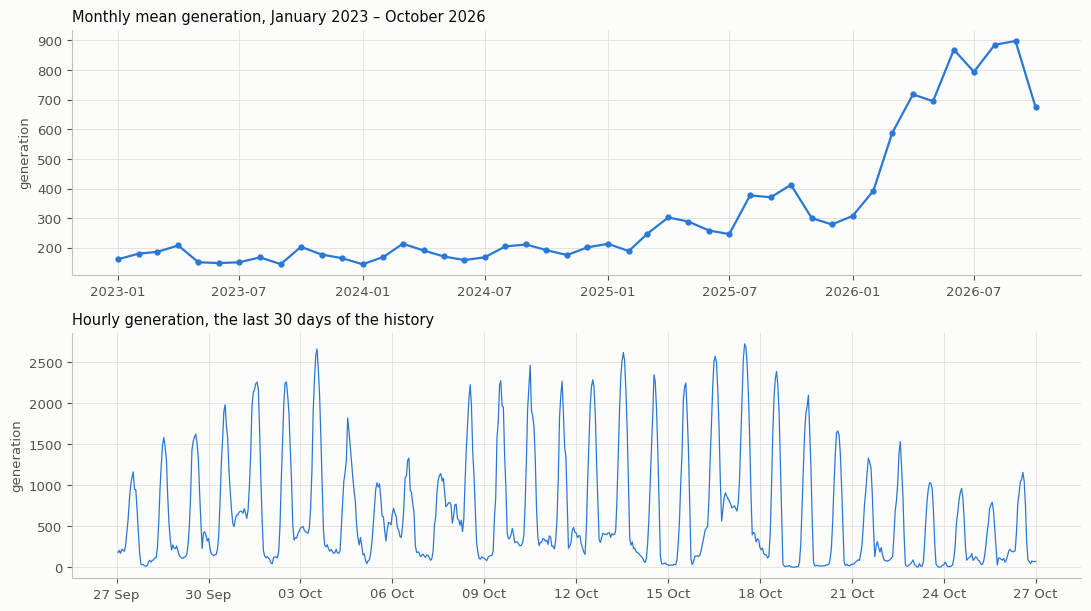

mean generation by year: {2023: 171, 2024: 184, 2025: 291, 2026: 684}


daily mean of the last 16 days: {'11 Oct': 763, '12 Oct': 843, '13 Oct': 980, '14 Oct': 627, '15 Oct': 618, '16 Oct': 1101, '17 Oct': 1139, '18 Oct': 704, '19 Oct': 560, '20 Oct': 474, '21 Oct': 455, '22 Oct': 389, '23 Oct': 287, '24 Oct': 289, '25 Oct': 256, '26 Oct': 390}


In [2]:
monthly = data.set_index("ds")["y"].resample("MS").mean()
fig, axes = plt.subplots(2, 1, figsize=(11, 6.2))
axes[0].plot(monthly.index, monthly.values, color=BLUE, marker="o", ms=3.5)
axes[0].set_title("Monthly mean generation, January 2023 – October 2026")
axes[1].plot(data["ds"].iloc[-30 * DAY:], y[-30 * DAY:], color=BLUE, lw=0.9)
axes[1].set_title("Hourly generation, the last 30 days of the history")
date_axis(axes[1], every=3)
for ax in axes:
    ax.set_ylabel("generation")
plt.tight_layout()
plt.show()
print("mean generation by year:", data.groupby(data["ds"].dt.year)["y"].mean().round(0).astype(int).to_dict())
day_of = (data["ds"] - pd.Timedelta(hours=1)).dt.strftime("%d %b")          # 00:00 closes the previous day
last16 = data.iloc[-16 * DAY:].groupby(day_of.iloc[-16 * DAY:], sort=False)["y"].mean().round(0).astype(int)
print("daily mean of the last 16 days:", last16.to_dict())

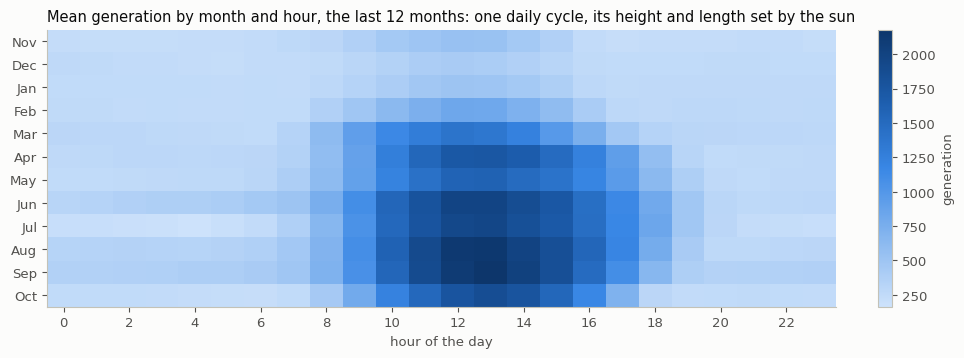

mean by day of week (Mon..Sun): [299, 308, 321, 322, 324, 326, 310] -> no weekly cycle


In [3]:
frame = data.assign(hour=data["ds"].dt.hour, month=data["ds"].dt.month)
heat = frame[frame["ds"] >= "2025-11-01"].pivot_table(index="month", columns="hour", values="y", aggfunc="mean")
heat = heat.loc[[11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]]
names = ["Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"]
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(heat, aspect="auto", cmap=BLUES)
ax.set_yticks(range(12), names)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of the day")
ax.grid(False)
ax.set_title("Mean generation by month and hour, the last 12 months: one daily cycle, its height and length set by the sun")
fig.colorbar(im, ax=ax, fraction=0.025, label="generation")
plt.show()
dow = frame.groupby(data["ds"].dt.dayofweek)["y"].mean()
print("mean by day of week (Mon..Sun):", dow.round(0).astype(int).tolist(), "-> no weekly cycle")

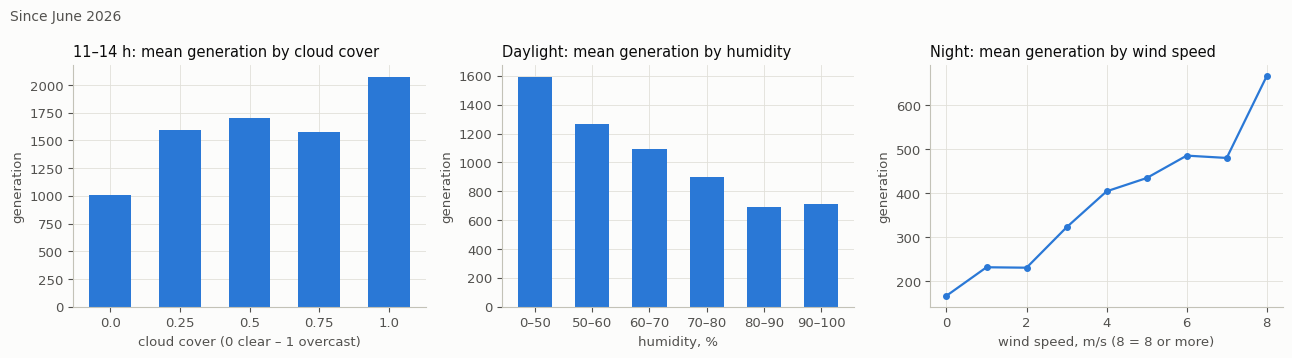

correlation with generation in daylight hours since June 2026: {'humidity': -0.57, 'cloud_cover': 0.16, 'temperature': 0.43, 'wind_speed': 0.34, 'pressure': 0.16}
share of 11-14 h hours coded cloud cover 1.0: 0.7


In [4]:
since = data[data["ds"] >= "2026-06-01"]
lit, dark = since[since["daylight"] == 1], since[since["daylight"] == 0]
noon = since[since["ds"].dt.hour.isin([11, 12, 13, 14])]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
by_cloud = noon.groupby("cloud_cover")["y"].mean()
axes[0].bar(by_cloud.index.astype(str), by_cloud.values, color=BLUE, width=0.6)
axes[0].set_title("11–14 h: mean generation by cloud cover")
axes[0].set_xlabel("cloud cover (0 clear – 1 overcast)")
hb = lit.groupby(pd.cut(lit["humidity"], [0, 50, 60, 70, 80, 90, 101]), observed=True)["y"].mean()
axes[1].bar([f"{int(i.left)}–{min(int(i.right), 100)}" for i in hb.index], hb.values, color=BLUE, width=0.6)
axes[1].set_title("Daylight: mean generation by humidity")
axes[1].set_xlabel("humidity, %")
wd = dark.groupby(dark["wind_speed"].clip(upper=8))["y"].mean()
axes[2].plot(wd.index, wd.values, color=BLUE, marker="o", ms=4)
axes[2].set_title("Night: mean generation by wind speed")
axes[2].set_xlabel("wind speed, m/s (8 = 8 or more)")
for ax in axes:
    ax.set_ylabel("generation")
plt.suptitle("Since June 2026", x=0.01, ha="left", fontsize=10, color=INK2)
plt.tight_layout()
plt.show()
print("correlation with generation in daylight hours since June 2026:",
      lit[["humidity", "cloud_cover", "temperature", "wind_speed", "pressure"]].corrwith(lit["y"]).round(2).to_dict())
print("share of 11-14 h hours coded cloud cover 1.0:", round((noon["cloud_cover"] == 1).mean(), 2))

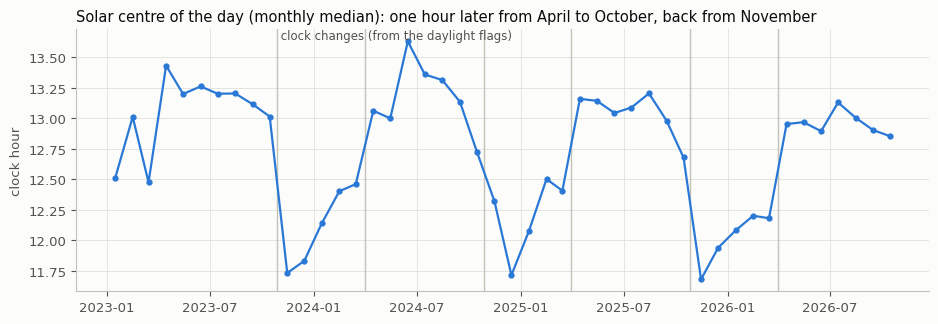

first daylight hour: 8:00 on 26 October (last day of the history), 7:00 on 27 October (the forecast)


In [5]:
# When does the sun's output sit on the clock? The solar centre of each day: the output-weighted mean hour of the
# daylight hours, after removing the wind level (the dark hours on both sides); clear-signal days only
d = data.assign(date=(data["ds"] - pd.Timedelta(hours=1)).dt.normalize(), hour=data["ds"].dt.hour.replace(0, 24))
piv, flag = d.pivot_table(index="date", columns="hour", values="y"), d.pivot_table(index="date", columns="hour", values="daylight")
rows = []
for day in piv.index:
    lit_h = [h for h in range(1, 25) if flag.loc[day, h] == 1]
    if not lit_h or min(lit_h) - 3 < 1 or max(lit_h) + 4 > 24:
        continue
    f0, l0 = min(lit_h), max(lit_h)
    hrs = np.arange(f0 - 2, l0 + 4)
    base = np.interp(hrs, [f0 - 3, l0 + 4], [piv.loc[day, f0 - 3], piv.loc[day, l0 + 4]])
    s = np.clip(piv.loc[day, hrs].to_numpy(float) - base, 0, None)
    if s.max() >= 150:
        rows.append({"date": day, "centre": (s * hrs).sum() / s.sum(), "first lit hour": f0})
cen = pd.DataFrame(rows).set_index("date")
m = cen.resample("MS").median()
first_lit = d[d["daylight"] == 1].groupby("date")["hour"].min()
shifts = first_lit[first_lit.diff().abs() > 0]
shifts = shifts[[(s.month == 3 and s.day >= 25) or (s.month == 10 and s.day >= 20) for s in shifts.index]]
fig, ax = plt.subplots(figsize=(11, 3.4))
for s in shifts.index:
    ax.axvline(s, color=AXIS, lw=1)
ax.plot(m.index + pd.Timedelta(days=14), m["centre"], color=BLUE, marker="o", ms=3.5)
ax.text(shifts.index[0], ax.get_ylim()[1], " clock changes (from the daylight flags)", color=INK2, fontsize=8.5, va="top")
ax.set_title("Solar centre of the day (monthly median): one hour later from April to October, back from November")
ax.set_ylabel("clock hour")
plt.show()
first_hist = data.iloc[-DAY:].loc[data["daylight"].iloc[-DAY:] == 1, "ds"].dt.hour.min()
first_fc = wf.iloc[:DAY].loc[wf["daylight"].iloc[:DAY] == 1, "ds"].dt.hour.min()
print(f"first daylight hour: {first_hist}:00 on 26 October (last day of the history), {first_fc}:00 on 27 October (the forecast)")

**What the series contains**

1. **A portfolio that grows.** Mean generation went from about 170 (2023) to about 680 (2026), most of it new capacity
   in 2026 on top of the summer season. Only recent history describes today's level. *→* classical models are fitted
   on a few weeks; LightGBM forecasts relative to the last week's level, so it does not learn 2023's level.
2. **One daily cycle, no weekly one.** The 24-hour period carries ~44% of the periodogram's power and the daily
   season's strength on the last 12 weeks is $F_S = 0.91$; day-of-week means are flat (generation does not care about
   weekends; $F_S$ for 168 hours is 0.11). *→* one season, $m = 24$.
3. **A multiplicative season.** The daily swing grows with the daily level (corr. 0.92). Box-Cox with Guerrero's
   $\lambda \approx 0.45$ removes the link, the log over-corrects; every family was fitted on both scales and the
   windows decided (the log suits MAPE: its errors are percentages).
4. **Day = sun, night = wind.** In daylight **humidity** is the strongest weather driver (corr. ≈ −0.6: fog and haze
   cut the sun), while **cloud cover works backwards** in this data — the "overcast" (1.0) noon hours are the most
   productive. At night generation rises with wind speed (≈ 170 at calm → ≈ 500 at 6 m/s), but the station's wind
   explains it only loosely (Spearman ≈ 0.4). *→* the models get every weather column and learn the relations
   themselves (trees, the foundation model's covariates) rather than a physics formula.
5. **Near-zero nights.** Calm nights fall to single digits (the minimum is 0.7). MAPE divides by the actual value, so
   these hours dominate it. *→* the night rule (Section 2).
6. **Weather systems of 4–5 days** (periods of ~100–120 hours) — invisible to a univariate model. *→* weather
   regressors.
7. **The clock changes.** The daylight flags move one hour at the end of March and October, and the output moves
   with them (the figure above) — in past years within a few days of the flags. **The forecast starts exactly at the
   October change:** the flags put sunrise one hour earlier on 27 October. The timing of the sunrise and sunset ramps
   on the hidden days is therefore uncertain. *→* the two members disagree here (Timestral follows the old clock,
   LightGBM the flags) and their average hedges; the interval covers both timings (Section 3).
8. **The last week fell.** Daily means went from ≈ 620–1,140 in mid-October (11–17 October) to ≈ 260–390 in the
   last four days (shorter, foggier days); the 48 hours ahead are forecast very humid. The seasonal naive copies
   26 October and cannot see any of it.

## 2. How did you check the forecast before submitting it?

**The protocol.** 20 rolling windows, one forecast origin every midnight from 6 to 25 October 2026; each window
forecasts 48 hours from the data before its origin only (window 1 is the template's validation window, 25–26
October). Every model — about 560 variants from four notebooks and Colab — ran on the **same** windows and was scored
with the template's metrics next to the template's seasonal naive, as **skill = score ÷ seasonal naive's score**
(below 1 is better). The main judge is **day 2** (hours 25–48, the private part).

Anything tuned on the windows' errors (the night rule, the interval recipe) was tuned **without the scored window and
its two neighbours** — neighbouring windows share a day — so the scores below are honest held-out scores
(*purged leave-one-window-out*).

,family,RMSE skill,MAPE skill,Winkler skill,coverage,windows beating SNAIVE (RMSE)
best foundation + best other,"pair, no night rule",0.581,0.160,0.357,0.954,18
best foundation + best other [post],final: pair + night rule,0.589,0.061,0.357,0.954,18
"Timestral 209M + weather, ctx 32768",foundation,0.616,0.118,0.357,0.954,16
"LightGBM relative log, 730d",LightGBM,0.677,0.207,NaN,NaN,17
"HistGB relative log, 730d",trees,0.678,0.244,NaN,NaN,16
"weather regression a=30 + ETS(A,N,N) bc, 26w",ETS + weather,0.700,0.534,0.467,0.935,17
"DHR K=5 + weather + sun log, 8w",ARIMAX / DHR,0.709,0.472,0.902,0.831,18
"Prophet + weather + sun log, 120d",Prophet,0.781,0.306,0.660,0.808,16
NHITS s1 + weather,neural,0.797,0.361,1.972,0.273,13
"daily ETS(A,Ad,N) x profile bc, 28d",ETS top-down,0.831,0.449,0.844,0.725,14


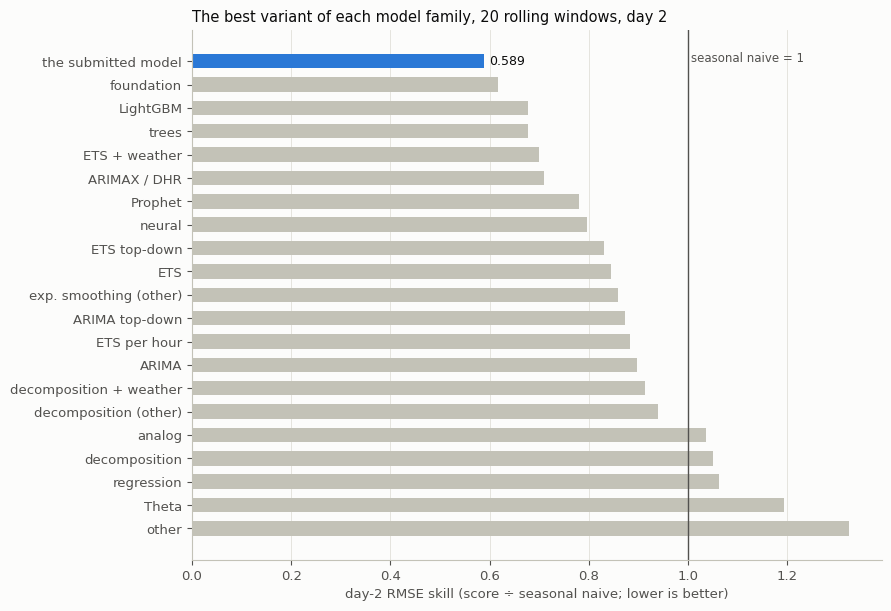

In [6]:
skip = {"simple", "combination", "post-processed"}
singles = board2[[family.get(n, "?") not in skip and n != "benchmark" for n in board2.index]].copy()
singles["family"] = [family.get(n, "?") for n in singles.index]
best = singles.sort_values("RMSE skill").groupby("family").head(1)
best = pd.concat([board2.loc[[CHOICE, BASE]], best])
best["family"] = best["family"].fillna("final: pair + night rule").where(best.index != BASE, "pair, no night rule")
table = best[["family", "RMSE skill", "MAPE skill", "Winkler skill", "coverage", "beat bench"]].sort_values("RMSE skill")
display(table.round(3).rename(columns={"beat bench": "windows beating SNAIVE (RMSE)"}))

top = table.drop(index=[BASE]).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6.2))
colors = [BLUE if n == CHOICE else AXIS for n in top.index]
labels = [f"{r.family}" if n != CHOICE else "the submitted model" for n, r in top.iterrows()]
ax.barh(labels, top["RMSE skill"], color=colors, height=0.62)
ax.axvline(1, color=INK2, lw=1)
ax.text(1.005, len(top) - 0.6, "seasonal naive = 1", color=INK2, fontsize=8.5, va="top")
ax.text(top.loc[CHOICE, "RMSE skill"] + 0.01, list(top.index).index(CHOICE), f"{top.loc[CHOICE, 'RMSE skill']:.3f}",
        va="center", color=INK, fontsize=9)
ax.set_xlabel("day-2 RMSE skill (score ÷ seasonal naive; lower is better)")
ax.set_title("The best variant of each model family, 20 rolling windows, day 2")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**What the windows showed.**

- **The foundation models win, and they win together.** The best variants were all Timestral (RMSE skill ≈ 0.62),
  ahead of Chronos-2, TimesFM and TimeGPT; their errors correlate strongly, so averaging several of them gained
  little (the top-3 and top-5 averages scored 0.625 and 0.637).
- **A pair of two different kinds of model wins more.** The best foundation model + the best *other* model (LightGBM
  on the weather) scored 0.581: their errors are much less correlated. It mattered most at the end of the period:
  in the last week the level fell, Timestral (reading the long history) kept over-forecasting while LightGBM
  (anchored to the last week) followed — on the five most recent windows the pair's RMSE skill is 0.44 against
  0.82 for Timestral and 0.63 for LightGBM.
- **The night rule.** At night the actual can be ~1, and MAPE punishes an over-forecast of a small value without
  bound but an under-forecast by at most 100%. The MAPE-optimal forecast is therefore *below* the median: for a
  lognormal error with log-spread $\sigma$ it is the median $\times\, e^{-\sigma^2}$ (the median of the
  $1/y$-weighted distribution). The tuned rule — forecasts below 100 times 0.1 — cut the MAPE skill from 0.160 to
  0.061 for an RMSE skill of 0.589 instead of 0.581.

In [7]:
low = d2[(d2["daylight"] == 0) & (d2[BASE] < 100)]
sig = np.std(np.log(low["actual"] / low[BASE]))
display(Markdown(f"*On the night hours where the pair forecasts below 100, the log-spread of actual ÷ forecast is "
                 f"σ ≈ {sig:.2f}, so the lognormal rule gives a factor of e<sup>−σ²</sup> ≈ {np.exp(-sig ** 2):.2f}; "
                 f"the factor tuned on held-out windows is {float(choice['night rule a']):.2f} at level "
                 f"{int(float(choice['night rule level']))}.*"))

*On the night hours where the pair forecasts below 100, the log-spread of actual ÷ forecast is σ ≈ 1.44, so the lognormal rule gives a factor of e<sup>−σ²</sup> ≈ 0.13; the factor tuned on held-out windows is 0.10 at level 100.*

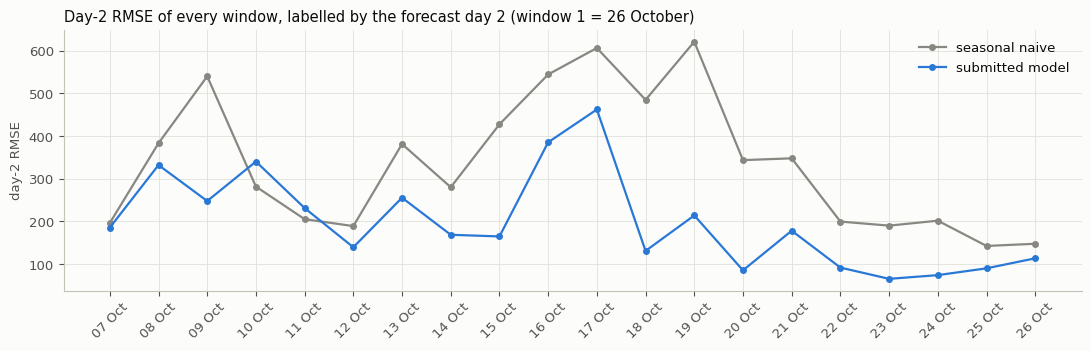

windows where the submitted model beat the seasonal naive, day 2:


,RMSE,MAPE,Winkler,all three
all 20 windows,18 of 20,15 of 20,16 of 20,12 of 20
5 most recent,5 of 5,2 of 5,3 of 5,1 of 5
15 older,13 of 15,13 of 15,13 of 15,11 of 15


In [8]:
dates2 = d2.groupby("window")["ds"].first().pipe(pd.to_datetime).dt.strftime("%d %b")
fig, ax = plt.subplots(figsize=(11, 3.6))
x = np.arange(20, 0, -1)
ax.plot(dates2.loc[x], sn2.loc[x, "RMSE"], color=MUTED, marker="o", ms=4, label="seasonal naive")
ax.plot(dates2.loc[x], ours2.loc[x, "RMSE"], color=BLUE, marker="o", ms=4, label="submitted model")
ax.set_ylabel("day-2 RMSE")
ax.set_title("Day-2 RMSE of every window, labelled by the forecast day 2 (window 1 = 26 October)")
ax.legend(loc="upper right")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
recent, older = list(range(1, 6)), list(range(6, 21))
tab = pd.DataFrame({f"{lab}": {m: f"{beat.loc[ws, m].sum()} of {len(ws)}" for m in ["RMSE", "MAPE", "Winkler"]}
                    for lab, ws in (("all 20 windows", list(range(1, 21))), ("5 most recent", recent), ("15 older", older))}).T
tab["all three"] = [f"{beat.loc[ws].all(axis=1).sum()} of {len(ws)}" for ws in (list(range(1, 21)), recent, older)]
print("windows where the submitted model beat the seasonal naive, day 2:")
display(tab)

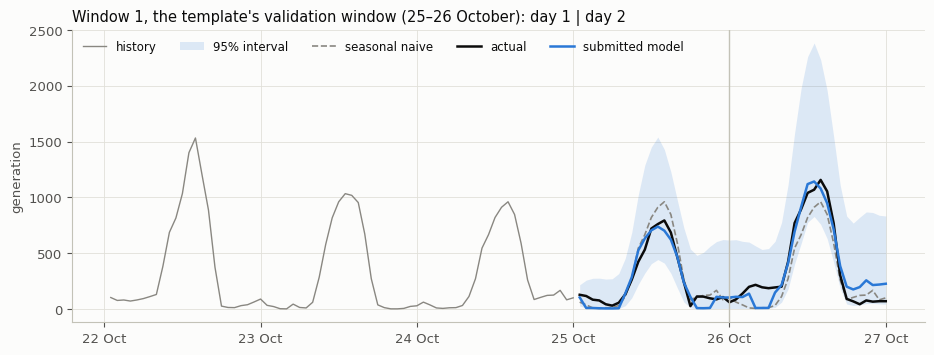

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.4,51.1,568.5,1.0
submitted model,92.3,69.7,743.4,1.0


In [9]:
w1 = bt[bt["window"] == 1]
fig, ax = plt.subplots(figsize=(11, 3.8))
hist = data.iloc[N - 2 * DAY - 3 * DAY:N - 2 * DAY]
ax.plot(hist["ds"], hist["y"], color=MUTED, lw=1, label="history")
ax.fill_between(w1["ds"], w1[f"{CHOICE} lo"], w1[f"{CHOICE} hi"], color=BLUE, alpha=0.15, lw=0, label="95% interval")
ax.plot(w1["ds"], w1["benchmark"], color=MUTED, lw=1.2, ls="--", label="seasonal naive")
ax.plot(w1["ds"], w1["actual"], color=INK, lw=1.8, label="actual")
ax.plot(w1["ds"], w1[CHOICE], color=BLUE, lw=1.8, label="submitted model")
ax.axvline(w1["ds"].iloc[DAY - 1], color=AXIS, lw=1)
ax.set_title("Window 1, the template's validation window (25–26 October): day 1 | day 2")
ax.set_ylabel("generation")
ax.legend(loc="upper left", ncol=5, fontsize=8.5)
date_axis(ax, every=1)
plt.show()
sc = lambda f, lo, hi: pd.Series({"RMSE": np.sqrt(np.mean((w1["actual"] - f) ** 2)), "MAPE": np.mean(np.abs((w1["actual"] - f) / w1["actual"])) * 100,
                                  "Winkler": np.mean((hi - lo) + 40 * (np.clip(lo - w1["actual"], 0, None) + np.clip(w1["actual"] - hi, 0, None))),
                                  "coverage": np.mean((w1["actual"] >= lo) & (w1["actual"] <= hi))})
display(pd.DataFrame({"seasonal naive": sc(w1["benchmark"], w1["benchmark lo"], w1["benchmark hi"]),
                      "submitted model": sc(w1[CHOICE], w1[f"{CHOICE} lo"], w1[f"{CHOICE} hi"])}).T.round(1))

**Reading the validation window honestly.** On 25–26 October the model beat the seasonal naive on RMSE (it followed
the day's shape and level) but **lost on MAPE and Winkler**. Those nights were steady, without near-zero hours: the
night rule's bet on a calm night cost ~90% error on each shaded hour, while yesterday's nights — the seasonal naive —
were close; and on a calm day the seasonal naive's narrower interval wins. Over all 20 windows the same pattern
holds: the model beats the seasonal naive on RMSE almost always (18 of 20), on MAPE in 15 and on Winkler in 16, on all
three at once in 12 — and **least often in the most recent, calm week**.

**The choice.** The ranking stand-in — 0.3 · RMSE skill + 0.3 · MAPE skill + 0.4 · Winkler skill on day 2, each
model with its best interval recipe judged on held-out windows — put the pair with the night rule first:

In [10]:
display(ranking[["interval", "RMSE skill", "MAPE skill", "Winkler skill", "coverage", "beat bench", "ranking score",
                 "RMSE skill, recent 5", "RMSE skill, other 15"]].head(6).round(3))

,interval,RMSE skill,MAPE skill,Winkler skill,coverage,beat bench,ranking score,"RMSE skill, recent 5","RMSE skill, other 15"
model,,,,,,,,,
best foundation + best other [post],own interval,0.589,0.061,0.357,0.954,18,0.338,0.493,0.604
"Timestral 209M + weather, ctx 32768 [post]",own interval,0.622,0.061,0.357,0.954,16,0.348,0.850,0.588
top-3 models average [post],median of 3 best intervals,0.634,0.061,0.353,0.960,17,0.350,1.058,0.570
"Timestral 123M + weather, ctx 32768 [post]",own interval,0.649,0.063,0.352,0.958,15,0.354,1.122,0.577
"Timestral 209M + weather, ctx 32768 [hybrid]",own interval,0.616,0.118,0.357,0.954,16,0.363,0.819,0.585
"Timestral 209M + weather, ctx 32768",own interval,0.616,0.118,0.357,0.954,16,0.363,0.819,0.585


## 3. How good is your interval?

**How it is built.** The foundation model forecasts quantiles; its 2.5% and 97.5% quantiles are the interval
(Timestral reads the weather too, so the interval widens where the weather makes the day uncertain). LightGBM has no
interval of its own, so the pair uses **Timestral's interval, stretched where needed to contain the averaged point**;
the night rule's lower point stretches the lower bound to it (the lower bound stays at 0 or above).

**How it was checked.** On the 20 windows, held out the same way, against the alternatives a model can have:

In [11]:
bench_w = sn2["Winkler"].mean()
rec = recipes.copy()
rec["Winkler skill"] = rec["Winkler"] / bench_w
display(rec[["Winkler", "Winkler skill", "coverage", "width"]].sort_values("Winkler").round(3))
print(f"the seasonal naive's own interval: day-2 Winkler {bench_w:.0f}, coverage {np.mean((d2['actual'] >= d2['benchmark lo']) & (d2['actual'] <= d2['benchmark hi'])):.3f}")

,Winkler,Winkler skill,coverage,width
recipe,,,,
own interval,978.539,0.357,0.954,783.221
median of 3 best intervals,979.320,0.357,0.962,785.413
own interval x c,1099.593,0.401,0.952,829.479
conformal,1261.583,0.460,0.938,818.995
conformal day/night,1373.729,0.501,0.933,818.401


the seasonal naive's own interval: day-2 Winkler 2740, coverage 0.817


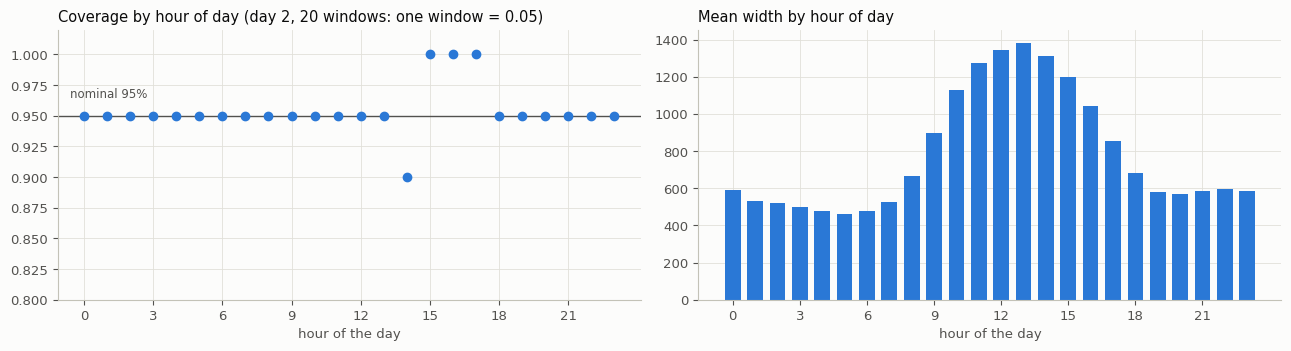

5 most recent windows: coverage 1.000, Winkler skill 0.912
15 older windows: coverage 0.939, Winkler skill 0.314
misses below / above the interval, day 2: 1 / 21


In [12]:
byh = d2.groupby("hour").agg(coverage=("inside", "mean"))
byh["width"] = d2.assign(w=d2[f"{CHOICE} hi"] - d2[f"{CHOICE} lo"]).groupby("hour")["w"].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].axhline(0.95, color=INK2, lw=1)
axes[0].plot(byh.index, byh["coverage"], color=BLUE, marker="o", ms=6, lw=0)
axes[0].text(-0.6, 0.962, "nominal 95%", color=INK2, fontsize=8.5, ha="left", va="bottom")
axes[0].set_ylim(0.8, 1.02)
axes[0].set_title("Coverage by hour of day (day 2, 20 windows: one window = 0.05)")
axes[1].bar(byh.index, byh["width"], color=BLUE, width=0.7)
axes[1].set_title("Mean width by hour of day")
for ax in axes:
    ax.set_xlabel("hour of the day")
    ax.set_xticks(range(0, 24, 3))
plt.tight_layout()
plt.show()
below, above = int((d2["actual"] < d2[f"{CHOICE} lo"]).sum()), int((d2["actual"] > d2[f"{CHOICE} hi"]).sum())
for lab, ws in (("5 most recent windows", recent), ("15 older windows", older)):
    k = d2["window"].isin(ws)
    print(f"{lab}: coverage {d2.loc[k, 'inside'].mean():.3f}, Winkler skill {ours2.loc[ws, 'Winkler'].mean() / sn2.loc[ws, 'Winkler'].mean():.3f}")
print(f"misses below / above the interval, day 2: {below} / {above}")

**What this says.**

- **Calibrated on average.** 95.4% of the day-2 hours fall inside a nominal 95% interval, and its Winkler score is
  about a third of the seasonal naive's (skill 0.357). None of the alternatives did better on held-out windows:
  scaling it by a factor tuned on the other windows (0.401), conformal intervals from the pair's errors (0.460; by day
  and night 0.501). A wider follow-up study on the saved results — conformal intervals at levels from 80% to 99%,
  asymmetric, scaled by the forecast or by Timestral's own width, on the log scale, and conformalised corrections of
  Timestral's bounds — reached 0.359–0.363 at best. Every recipe that narrowed it paid in misses: the Winkler score
  charges 40× the distance of every miss.
- **Its shape is not perfect.** The misses are almost all *above* the interval (bright days, Section 4); the afternoon
  hours never missed (wider than needed) and 14:00 covered least.
- **It is too wide in a calm week.** On the five most recent windows it covered every hour and its Winkler score was
  close to the seasonal naive's. Narrowing it from the most recent windows (an adaptive, conformal-style width) was
  tried and lost in 11–12 of the windows where it could be tested: a calm week is often followed by a volatile day.
  The public leaderboard then showed the same width on a hidden day (below).
- **The clock change.** On 28 October the interval at the sunset hours is wide enough for either timing: at 16:00
  it spans ≈ 204–1307, which holds both the summer pattern (≈ 460–770 at that hour in the last week) and the winter
  one (≈ 240–300); at 17:00 it spans ≈ 52–905.
- **A pooled interval** — the median of the three best models' intervals — tied it on held-out windows (979 vs 979
  on day 2; 2% worse on day 1); the single interval was kept.

### After the public leaderboard

On Thursday 5 November the public leaderboard scored the first 24 hidden hours (27 October) of the file made with
the interval above. The point forecast did well and the interval did not:

In [13]:
display(public)
print(f"mean width of our interval on 27 October: {(sub['upper_95'] - sub['lower_95'])[:DAY].mean():.0f}")

,RMSE,MAPE,Winkler,coverage
this model (2.13),81.7,38.2,741,1.0
seasonal naive,115.7,84.3,521,1.0


mean width of our interval on 27 October: 741


Every hour fell inside both intervals, so both Winkler scores are just mean widths: ours was 42% wider than the
seasonal naive's. This is the calm-week weakness above, now on a hidden day. On day 2 the seasonal naive's interval is
697 wide on average and ours was 880, so on a calm 28 October it would win on Winkler even if ours covered every hour.

The width cannot simply be cut. The upper side and the night hold the real risks (all but one of the misses were
above: bright days and windy nights), and 28 October is forecast drier than the foggy days before it, the regime where
the misses fall above. One part of the interval had slack in every window: **the lower bound in the middle of the
day**. The change: on day 2, in the lit hours 09:00–14:00, the lower bound moves to point − 0.7 · (point − lower
bound); the hours around sunrise and sunset keep their bounds (the clock change). Unlike the upper-heavy reshaping in
Section 4's table, which moved the whole interval up and paid with misses below, it touches only those hours. The
factor 0.7 is a round step with room to spare, not tuned on the public score. Two checks:

1) the rolling windows: the change applied to each day of the 20 windows


,Winkler skill before,Winkler skill after,windows better,windows worse,misses below before,misses below after,closest approach to the old midday bound
day,,,,,,,
1,0.295,0.290,19,1,3,7,1.464
2,0.357,0.343,20,0,1,1,0.557


2) 28 October scored against the last 21 real days as outcomes, old and new clock (42 scenarios)


,mean width,mean Winkler,worst,better than Section 2's (of 42),scenarios with a new miss
interval of Section 2,880.0,3031.0,10778.0,0,0
as submitted (midday change),846.0,2997.0,10744.0,42,0
change + night upper × 0.8,771.0,3218.0,11847.0,24,14
change + all upper × 0.8,709.0,4202.0,14062.0,13,26
seasonal naive,697.0,5072.0,15118.0,11,33


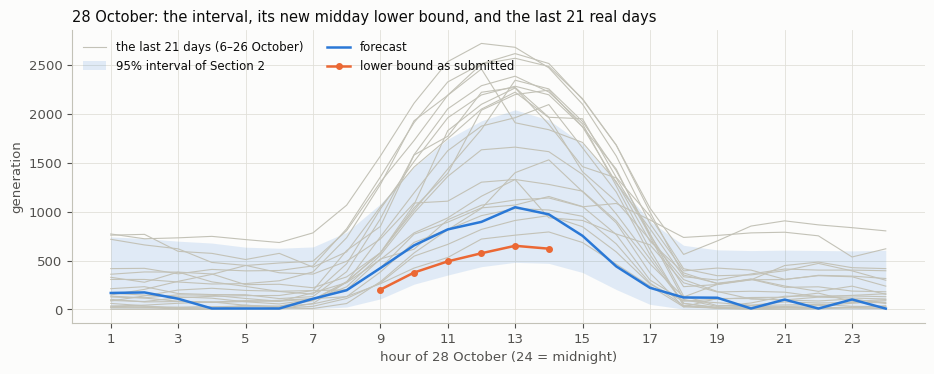

In [14]:
rows = []
for day in (1, 2):
    part = bt[bt["day"] == day]
    m = (bt["day"] == day) & (bt["daylight"] == 1) & bt["hour"].isin(MIDDAY)
    lo_k = LO.where(~m, F - SHRINK * (F - LO))
    before, after = window_scores(part, F, LO, HI)["Winkler"], window_scores(part, F, lo_k, HI)["Winkler"]
    bench = window_scores(part, bt["benchmark"], bt["benchmark lo"], bt["benchmark hi"])["Winkler"]
    a = part["actual"]
    rows.append({"day": day, "Winkler skill before": before.mean() / bench.mean(), "Winkler skill after": after.mean() / bench.mean(),
                 "windows better": int((after < before - 1e-9).sum()), "windows worse": int((after > before + 1e-9).sum()),
                 "misses below before": int((a < LO[part.index]).sum()), "misses below after": int((a < lo_k[part.index]).sum()),
                 "closest approach to the old midday bound": ((F - bt["actual"])[m] / (F - LO)[m]).max()})
print("1) the rolling windows: the change applied to each day of the 20 windows")
display(pd.DataFrame(rows).set_index("day").round(3))

# 2) 28 October against real days: each of the last 21 days of the history as the outcome, on the old clock and
#    moved one hour earlier (the new clock)
c2 = change.iloc[DAY:]
f28, lo_old, lo_new, hi28 = (c2[c].to_numpy() for c in ("forecast", "lower before", "lower after", "upper"))
dark28 = wf["daylight"].to_numpy()[DAY:2 * DAY] == 0
sig = np.std(y[DAY:] - y[:-DAY], ddof=1)
cands = {"interval of Section 2": (lo_old, hi28), "as submitted (midday change)": (lo_new, hi28),
         "change + night upper × 0.8": (lo_new, np.where(dark28, f28 + 0.8 * (hi28 - f28), hi28)),
         "change + all upper × 0.8": (lo_new, f28 + 0.8 * (hi28 - f28)),
         "seasonal naive": (np.clip(y[-DAY:] - 1.96 * sig * np.sqrt(2), 0, None), y[-DAY:] + 1.96 * sig * np.sqrt(2))}
wink = lambda a, lo_, hi_: np.mean((hi_ - lo_) + 40 * (np.clip(lo_ - a, 0, None) + np.clip(a - hi_, 0, None)))
scen = []
for k in range(21):
    prof = y[N - DAY * (k + 1):N - DAY * k]
    for clock, a in (("old clock", prof), ("new clock", np.r_[prof[1:], prof[-1]])):
        scen.append((a, {n: wink(a, *b) for n, b in cands.items()}, {n: ((a < b[0]) | (a > b[1])) for n, b in cands.items()}))
S = pd.DataFrame([s[1] for s in scen])
ref_miss = [s[2]["interval of Section 2"] for s in scen]
stress = pd.DataFrame({
    "mean width": {n: np.mean(b[1] - b[0]) for n, b in cands.items()},
    "mean Winkler": S.mean(), "worst": S.max(),
    "better than Section 2's (of 42)": {n: int((S[n] < S["interval of Section 2"] - 1e-9).sum()) for n in cands},
    "scenarios with a new miss": {n: sum(bool((s[2][n] & ~r).any()) for s, r in zip(scen, ref_miss)) for n in cands}})
print("2) 28 October scored against the last 21 real days as outcomes, old and new clock (42 scenarios)")
display(stress.round(0))

fig, ax = plt.subplots(figsize=(11, 3.8))
hrs = np.arange(1, DAY + 1)
for k in range(21):
    ax.plot(hrs, y[N - DAY * (k + 1):N - DAY * k], color=AXIS, lw=0.8)
ax.plot([], [], color=AXIS, lw=0.8, label="the last 21 days (6–26 October)")
ax.fill_between(hrs, lo_old, hi28, color=BLUE, alpha=0.13, lw=0, label="95% interval of Section 2")
ax.plot(hrs, f28, color=BLUE, lw=1.8, label="forecast")
moved = c2["changed"].to_numpy()
ax.plot(hrs[moved], lo_new[moved], color=ORANGE, lw=1.8, marker="o", ms=4, label="lower bound as submitted")
ax.set_xticks(range(1, DAY + 1, 2))
ax.set_xlabel("hour of 28 October (24 = midnight)")
ax.set_ylabel("generation")
ax.set_title("28 October: the interval, its new midday lower bound, and the last 21 real days")
ax.legend(loc="upper left", ncol=2, fontsize=8.5)
plt.show()

- **On the rolling windows** the change improves day 2 in all 20 windows (Winkler skill 0.357 → 0.343; the
  Winkler score now beats the seasonal naive's in 17 windows instead of 16) without a single new miss: the actual came
  at most 0.56 of the way from the point down to the old bound. On day 1 it would have added 4 misses below, so it is
  used on day 2 only (day 1 was already scored).
- **Against the last 21 real days** as outcomes for 28 October, on both clocks, it is better than the old interval in
  every scenario, with no new miss. The closest call is 25 October, the darkest day of the last three weeks: its
  midday hours stay 40–170 above the new bound, so a 28 October darker than that would cross it. The day-2 width
  falls from 880 to 846: a small change, and the safe one.
- **Cutting more was rejected.** Narrowing the night's upper bound as well (× 0.8) gains about 50 in most windows but
  loses about 900 in each of the two windows with windy nights (16–17 October), and it beats the old interval in only
  about half of the scenarios; cutting the whole upper side does worse. The width it would remove is the cover for the
  real risks, and on a calm 28 October we accept losing the Winkler score to the seasonal naive's narrower interval.

## 4. What is left, and what did not work?

### The residuals of the final model

In [15]:
lit2 = d2[d2["daylight"] == 1]
summary = pd.DataFrame({
    "mean error (+ = too low)": [d2["e"].mean(), lit2["e"].mean(), d2.loc[d2["daylight"] == 0, "e"].mean()],
    "RMSE": [np.sqrt((d2["e"] ** 2).mean()), np.sqrt((lit2["e"] ** 2).mean()), np.sqrt((d2.loc[d2["daylight"] == 0, "e"] ** 2).mean())],
    "share of hours too low": [(d2["e"] > 0).mean(), (lit2["e"] > 0).mean(), (d2.loc[d2["daylight"] == 0, "e"] > 0).mean()]},
    index=["day 2, all hours", "day 2, daylight", "day 2, night"])
display(summary.round(2))
level_share = lit2.groupby("window")["e"].agg(lambda v: v.mean() ** 2 / (v ** 2).mean())
ac = d2.groupby("window")["e"].apply(lambda v: np.corrcoef(v.to_numpy()[:-1], v.to_numpy()[1:])[0, 1])
dd = bt.groupby(["window", "day"])["e"].mean().unstack()
print(f"share of a day's daylight squared error that is one level shift: median {level_share.median():.2f}")
print(f"lag-1 autocorrelation of the hourly errors: median {ac.median():.2f};  "
      f"correlation of a window's mean day-1 and day-2 errors: {np.corrcoef(dd[1], dd[2])[0, 1]:.2f}")

,mean error (+ = too low),RMSE,share of hours too low
"day 2, all hours",89.80,225.77,0.63
"day 2, daylight",146.46,287.30,0.65
"day 2, night",52.03,172.98,0.61


share of a day's daylight squared error that is one level shift: median 0.61
lag-1 autocorrelation of the hourly errors: median 0.81;  correlation of a window's mean day-1 and day-2 errors: 0.45


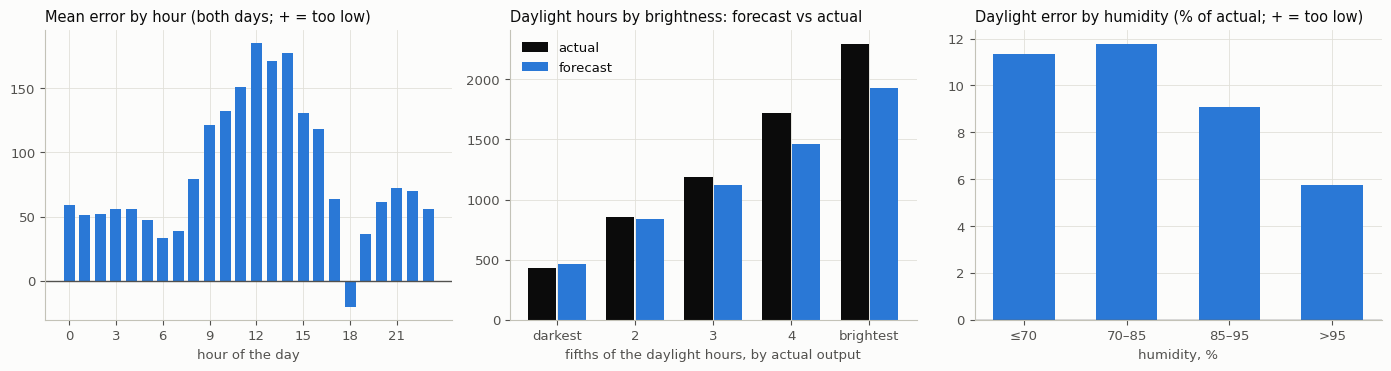

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
eh = bt.groupby("hour")["e"].mean()
axes[0].bar(eh.index, eh.values, color=BLUE, width=0.7)
axes[0].axhline(0, color=INK2, lw=1)
axes[0].set_title("Mean error by hour (both days; + = too low)")
axes[0].set_xlabel("hour of the day")
axes[0].set_xticks(range(0, 24, 3))
lb = bt[bt["daylight"] == 1].copy()
lb["fifth"] = pd.qcut(lb["actual"], 5, labels=["darkest", "2", "3", "4", "brightest"])
q = lb.groupby("fifth", observed=True).agg(actual=("actual", "mean"), forecast=(CHOICE, "mean"))
xq = np.arange(5)
axes[1].bar(xq - 0.19, q["actual"], width=0.36, color=INK, label="actual")
axes[1].bar(xq + 0.19, q["forecast"], width=0.36, color=BLUE, label="forecast")
axes[1].set_xticks(xq, q.index)
axes[1].set_title("Daylight hours by brightness: forecast vs actual")
axes[1].set_xlabel("fifths of the daylight hours, by actual output")
axes[1].legend(loc="upper left")
hb = lb.groupby(pd.cut(lb["humidity"], [0, 70, 85, 95, 101], labels=["≤70", "70–85", "85–95", ">95"]), observed=True)
pct = hb.apply(lambda g: 100 * g["e"].mean() / g["actual"].mean())
axes[2].bar(pct.index.astype(str), pct.values, color=BLUE, width=0.6)
axes[2].axhline(0, color=INK2, lw=1)
axes[2].set_title("Daylight error by humidity (% of actual; + = too low)")
axes[2].set_xlabel("humidity, %")
plt.tight_layout()
plt.show()

In [17]:
rows = []
for lab, ws in (("15 older windows", older), ("5 most recent windows", recent)):
    s = bt[bt["window"].isin(ws)]
    rows.append({"windows": lab, "RMSE Timestral": np.sqrt((s["eT"] ** 2).mean()), "RMSE LightGBM": np.sqrt((s["eL"] ** 2).mean()),
                 "RMSE pair (no night rule)": np.sqrt(((s["actual"] - s[BASE]) ** 2).mean()),
                 "bias Timestral (+ = too low)": s["eT"].mean(), "bias LightGBM": s["eL"].mean(),
                 "correlation of their errors": np.corrcoef(s["eT"], s["eL"])[0, 1]})
display(pd.DataFrame(rows).set_index("windows").round(2))

,RMSE Timestral,RMSE LightGBM,RMSE pair (no night rule),bias Timestral (+ = too low),bias LightGBM,correlation of their errors
windows,,,,,,
15 older windows,225.13,285.14,241.25,71.85,125.44,0.76
5 most recent windows,145.85,116.18,83.49,-58.72,32.85,-0.10


**What is left — the blind spots.**

| | Blind spot | Evidence |
|---|---|---|
| 1 | **Bright days come out too low** | Daylight hours are under-forecast on average, the brightest fifth by roughly 15–20% (figure above); the error grows with how much brighter a day is than the last three (Spearman 0.64). Both members do it, so the average keeps it. |
| 2 | **Dry days come out too low** | ≈ 11–12% too low in daylight hours below 85% humidity, ≈ 6% in fog (above 95%). |
| 3 | **The best weighting depends on the regime** | In the older windows both members are too low together (errors correlated); after the late-October fall Timestral is too high and LightGBM is not (errors uncorrelated) — the pair's equal weights are a compromise. |
| 4 | **The interval's shape** | Misses are almost all above it; the afternoon is wider than needed; windy nights that jump above it carry ~30% of the night Winkler score. |
| 5 | **Calm nights the rule misses** | Hours where the pair said ≈ 110 and the actual was ≈ 20 carry ~20% of the night MAPE; windy nights go far above (16 October: ≈ 900 against ≈ 200). |
| 6 | **Sunset hours** | The first dark hour still carries some sun; MAPE is ~100–130% in the 2–4 hours after sunset; the clock change makes these hours the most fragile on 27–28 October. |

**Most of the error is the day's level, not its shape**: about 60% of a day's squared daylight error is one shift of
the whole day, hourly errors move together (autocorrelation ≈ 0.8), and day 1's error carries into day 2 (≈ 0.45).
The thing that matters is how much sun and wind the day brings — the weather — not the hourly profile.

### What I tried and dropped

| Approach | What happened (day 2, held-out windows) | Why dropped |
|---|---|---|
| ETS / ARIMA / Theta / decomposition on 3 days – 26 weeks | best ETS variants 0.83–0.89 RMSE skill, best ARIMA 0.90, Theta 1.19 | the level moves faster than they adapt; no weather |
| DHR / ARIMAX / ETS + a weather regression | best 0.70 (weather regression + ETS on the daily residuals), DHR 0.71 | better, but behind the foundation models and LightGBM |
| cloud-cover interactions in linear models | over-forecast badly | cloud cover acts non-linearly (backwards) here |
| Prophet, neural networks (NHITS, NBEATSx, TiDE) | best 0.78–0.80; NHITS's interval covered 27% | behind; intervals unusable |
| LightGBM's own quantile interval | covered ~75% | too narrow |
| averages of the top 3 / top 5 models, best of each family | 0.625–0.73 | the foundation models err together |
| a separate night model (LightGBM quantiles on wind, recent nights) | night MAPE 135% vs 105%; its intervals covered 77% | worse point, overconfident interval |
| every one of 547 models as the night forecaster, alone or averaged with the pair | best single pick: RMSE 0.599 / MAPE 0.067 vs 0.589 / 0.061 | the pair already has the night information |
| night-rule variants (finer factors, smoothed or whole-night triggers, a two-step rule) | RMSE 0.591–0.623; MAPE gains only with RMSE losses, in about half the windows | noise |
| a calm-night classifier for the rule | it ranks calm hours well (AUC 0.87), but MAPE 0.073 | shades too many hours that were not calm |
| reshaping the whole interval upward (higher lower bound, more room above) | Winkler skill 0.392–0.404 | misses below the interval jumped to 21–30 hours |
| after the public day: narrowing the night or the whole upper side (× 0.8) | ≈ 50 better in most windows, ≈ 900 worse on each windy night (16–17 Oct); better than the old interval in about half of 42 real-day scenarios or fewer | the width covers the real risks; only the midday lower bound was changed (Section 3) |
| weights by humidity / by each member's recent errors; correcting each member by its recent bias | 0.630 / no gain / gains only in a few older windows, worse in the recent ones | they chase the last windows' noise |
| LightGBM without its weekly anchor; with "weather vs last week" inputs | 0.662 / alone better (0.689 vs 0.729) but in the pair 0.584 RMSE, MAPE 0.069, worse recently | no gain in the pair |
| a daylight multiplier keyed to humidity (×1.10–1.15 on dry days) | best average (RMSE 0.564, ranking score 0.330 vs 0.338), but on the 5 most recent windows 0.690 vs 0.493 | it learns early-October bright days; in the last week the pair was already high — it would raise 28 October by 10% |
| choosing variants to beat the seasonal naive on all three scores | 14–15 of 20 windows on the windows used to choose, 9–12 on held-out ones | selection noise |

The last line is the general lesson: with 20 windows, a choice made on the same windows it is scored on looks
better than it is; every decision above was checked on windows it had not seen, and most "improvements" disappeared
there.

**Next steps.** A daily-level model driven by the weather that learns from long history *and* knows the current
regime (the humidity multiplier above, made regime-aware); better use of the calm-night probability (a MAPE-optimal
point from it rather than a threshold); and explicit handling of the clock change for the sunrise and sunset hours.

### The submitted forecast

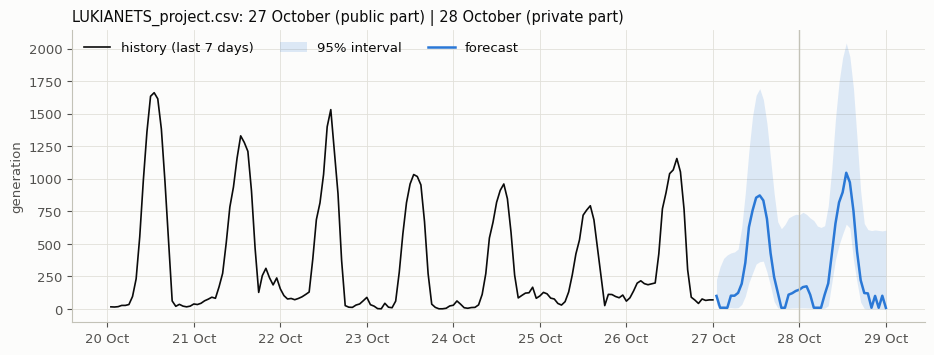

48 rows; lower <= forecast <= upper: True; lower >= 0: True; mean width day 1 741, day 2 846


In [18]:
fig, ax = plt.subplots(figsize=(11, 3.8))
h7 = data.iloc[-7 * DAY:]
ax.plot(h7["ds"], h7["y"], color=INK, lw=1.2, label="history (last 7 days)")
ax.fill_between(sub["ds"], sub["lower_95"], sub["upper_95"], color=BLUE, alpha=0.15, lw=0, label="95% interval")
ax.plot(sub["ds"], sub["forecast"], color=BLUE, lw=1.8, label="forecast")
ax.axvline(sub["ds"].iloc[DAY - 1], color=AXIS, lw=1)
ax.set_title("LUKIANETS_project.csv: 27 October (public part) | 28 October (private part)")
ax.set_ylabel("generation")
ax.legend(loc="upper left", ncol=3)
date_axis(ax, every=1)
plt.show()
print(f"48 rows; lower <= forecast <= upper: {bool(((sub['lower_95'] <= sub['forecast']) & (sub['forecast'] <= sub['upper_95'])).all())}; "
      f"lower >= 0: {bool((sub['lower_95'] >= 0).all())}; mean width day 1 {(sub['upper_95'] - sub['lower_95'])[:DAY].mean():.0f}, day 2 {(sub['upper_95'] - sub['lower_95'])[DAY:].mean():.0f}")